In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from config import PROCESSED
from utils import load_bg, load_stations, group_summary

pd.set_option("display.float_format", "{:,.2f}".format)

Walking distance from each block group centroid to the nearest public Level 2 station, Level 2 ports within an 800 m walk, and driving time to the nearest DC fast station. See `scripts/03_access_metrics.py`.

In [2]:
bg = load_bg()
bg[["walk_l2_m", "l2_ports_400", "l2_ports_800", "l2_ports_1200", "drive_dcfc_m", "drive_dcfc_min"]].describe()

,walk_l2_m,l2_ports_400,l2_ports_800,l2_ports_1200,drive_dcfc_m,drive_dcfc_min
count,"1,246.00","1,246.00","1,246.00","1,246.00","1,246.00","1,246.00"
mean,"2,078.70",0.48,2.21,5.59,"2,907.88",3.65
std,"1,237.25",2.40,7.43,15.53,"1,330.78",1.59
min,37.43,0.00,0.00,0.00,168.66,0.06
25%,"1,047.78",0.00,0.00,0.00,"1,835.20",2.43
50%,"1,972.95",0.00,0.00,0.00,"2,791.20",3.53
75%,"2,895.50",0.00,0.00,2.00,"3,891.20",4.82
max,"6,430.04",30.00,67.00,105.00,"7,074.02",8.32


In [3]:
print(f"Median walk to nearest L2: {bg.walk_l2_m.median():,.0f} m")
print(f"Block groups more than 1 mile (1,609 m) from L2: {(bg.walk_l2_m > 1609).sum()} of {len(bg)}")
print(f"Block groups with no L2 port within 800 m: {(bg.l2_ports_800 == 0).sum()}")

Median walk to nearest L2: 1,973 m
Block groups more than 1 mile (1,609 m) from L2: 754 of 1246
Block groups with no L2 port within 800 m: 1016


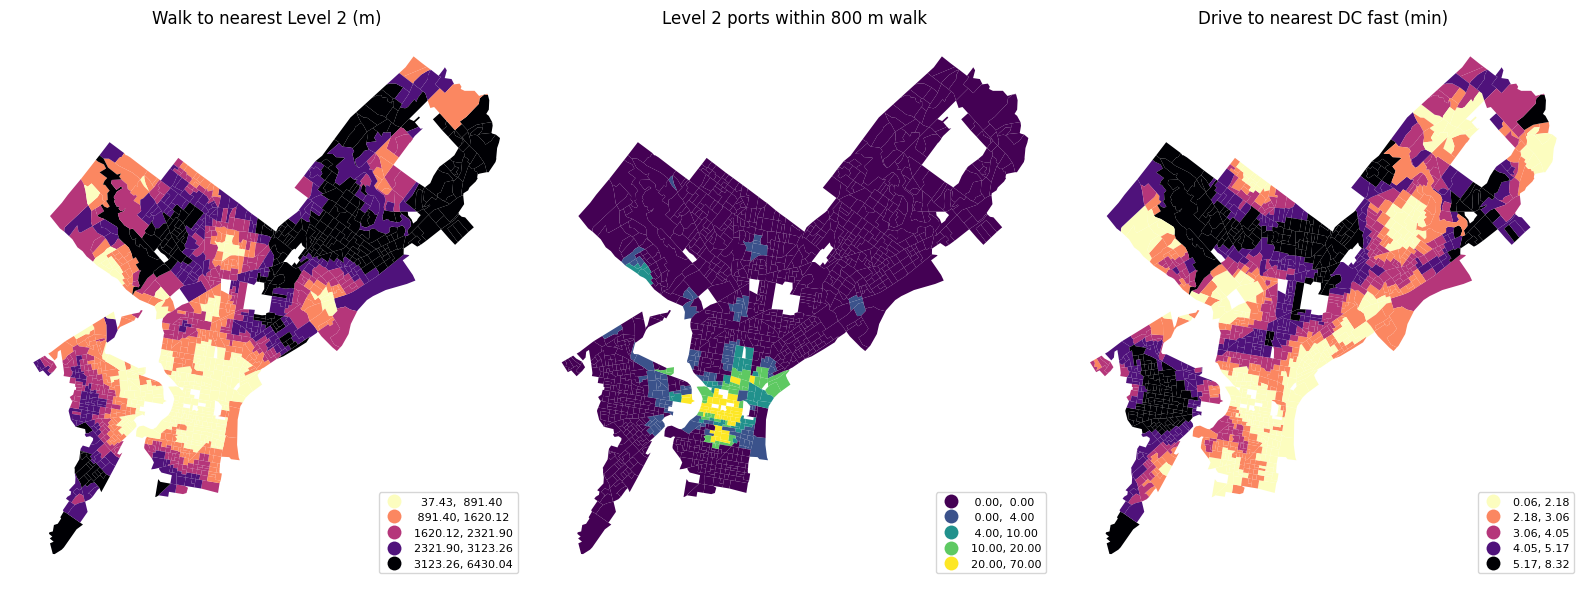

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 6))
specs = [("walk_l2_m", "Walk to nearest Level 2 (m)", "magma_r"),
         ("l2_ports_800", "Level 2 ports within 800 m walk", "viridis"),
         ("drive_dcfc_min", "Drive to nearest DC fast (min)", "magma_r")]
for ax, (col, title, cmap) in zip(axes, specs):
    # most block groups have zero nearby ports, so use fixed breaks for the port map
    kw = (dict(scheme="user_defined", classification_kwds={"bins": [0, 4, 10, 20, 70]})
          if col == "l2_ports_800" else dict(scheme="quantiles", k=5))
    bg.plot(column=col, cmap=cmap, legend=True, ax=ax,
            legend_kwds={"loc": "lower right", "fontsize": 8}, **kw)
    ax.set_title(title); ax.set_axis_off()
plt.tight_layout()

In [5]:
bg.explore(column="walk_l2_m", scheme="quantiles", k=5, cmap="magma_r", tiles="OpenStreetMap",
           tooltip=["GEOID", "walk_l2_m", "l2_ports_800", "drive_dcfc_min", "med_income", "garage_share"],
           legend_kwds={"caption": "Walk to nearest L2 (m)"})

## Sensitivity checks

**Station buffer.** Widening the station search from one to two miles beyond the city boundary.

In [6]:
d = bg.walk_l2_m - bg.walk_l2_wide_m
print(f"Block groups with a shorter walk under the 2-mile buffer: {(d > 1).sum()}")
print(f"Largest reduction: {d.max():,.0f} m")

Block groups with a shorter walk under the 2-mile buffer: 3
Largest reduction: 1,250 m


**Walking threshold.** Share of block groups with at least one Level 2 port within 400, 800, and 1,200 m.

In [7]:
pd.Series({c: (bg[f"l2_ports_{c}"] > 0).mean() for c in [400, 800, 1200]}, name="share with any port").to_frame()

,share with any port
400,0.07
800,0.18
1200,0.29
